In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import scanpy as sc
import seaborn as sns
from scipy.stats import false_discovery_control, mannwhitneyu, spearmanr

DIR_PROCESADOS = Path("../data/processed")
DIR_FIGURAS = Path("../results/figuras")
DIR_TABLAS = Path("../results/tablas")

tcel = sc.read_h5ad(DIR_PROCESADOS / "04_linfocitos_T.h5ad")
tcel

AnnData object with n_obs × n_vars = 1445 × 21761
    obs: 'donante', 'condicion', 'muestra', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'atipico', 'atipico_mt', 'pasa_qc', 'n_genes', 'doublet_score', 'predicted_doublet', 'leiden', 'es_T', 'tipo', 'leiden_T', 'subtipo_T'
    var: 'gene_ids', 'feature_types', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'condicion_colors', 'hvg', 'leiden', 'leiden_T', 'leiden_T_colors', 'leiden_colors', 'log1p', 'muestra_colors', 'neighbors', 'pca', 'rank_genes_groups', 'scrublet', 'tipo_color

In [2]:
firmas = {
    "TRM": ["CD69", "ITGAE", "CXCR6", "ITGA1", "PDCD1", "CD101", "CRTAM", "RGS1", "ZNF683"],
    "Th1": ["IFNG", "TBX21", "CXCR3", "IL12RB2", "STAT4"],
    "Th2": ["GATA3", "IL4", "IL5", "IL13", "CCR4", "PTGDR2"],
    "Th17": ["RORC", "IL17A", "IL17F", "IL22", "CCR6", "IL23R"],
    "Citotoxicidad": ["GZMA", "GZMB", "GZMK", "PRF1", "NKG7", "GNLY"],
    "Respuesta a IFN": ["STAT1", "IRF1", "GBP1", "GBP2", "GBP4", "GBP5", "IFI6", "ISG15", "MX1"],
}

for nombre, genes in firmas.items():
    presentes = [g for g in genes if g in tcel.var_names]
    faltan = sorted(set(genes) - set(presentes))
    print(f"{nombre}: {len(presentes)} de {len(genes)} genes. Faltan: {faltan}")
    sc.tl.score_genes(tcel, presentes, score_name=nombre, random_state=0)

TRM: 9 de 9 genes. Faltan: []
Th1: 5 de 5 genes. Faltan: []
Th2: 5 de 6 genes. Faltan: ['IL4']
Th17: 3 de 6 genes. Faltan: ['IL17A', 'IL17F', 'IL22']
Citotoxicidad: 6 de 6 genes. Faltan: []
Respuesta a IFN: 9 de 9 genes. Faltan: []


In [3]:
por_muestra = tcel.obs.groupby("muestra", observed=True)[list(firmas)].mean()
por_muestra["condicion"] = tcel.obs.groupby("muestra", observed=True)["condicion"].first()
por_muestra["n_T"] = tcel.obs["muestra"].value_counts()
por_muestra = por_muestra[por_muestra["n_T"] >= 20]
por_muestra.sort_values("condicion").round(3)

,TRM,Th1,Th2,Th17,Citotoxicidad,Respuesta a IFN,condicion,n_T
muestra,,,,,,,,
486_LS,-0.119,-0.021,-0.063,-0.145,0.043,0.202,LS,35
BIO023_LS,0.011,-0.050,-0.140,-0.078,-0.089,0.097,LS,23
DER114_LS,-0.002,-0.107,-0.099,-0.004,-0.086,0.041,LS,298
DER115_LS,-0.088,-0.103,-0.104,-0.018,0.017,0.026,LS,432
DER119_LS,-0.098,-0.115,-0.138,0.111,-0.123,0.049,LS,73
DER114_NL,-0.019,-0.068,-0.096,0.002,0.010,-0.012,NL,101
DER115_NL,0.004,-0.057,-0.106,-0.022,0.106,0.044,NL,200
DER119_NL,-0.118,-0.152,-0.070,0.200,-0.186,-0.005,NL,52
DER120_NL,-0.093,-0.152,-0.126,-0.064,-0.160,-0.000,NL,30


In [4]:
orden = {"Sano": 0, "NL": 1, "LS": 2}
filas = []
for s in firmas:
    g = {c: por_muestra.loc[por_muestra["condicion"] == c, s] for c in orden}
    rho = spearmanr(por_muestra["condicion"].map(orden), por_muestra[s])
    filas.append({"firma": s,
                  "mediana_Sano": g["Sano"].median(),
                  "mediana_NL": g["NL"].median(),
                  "mediana_LS": g["LS"].median(),
                  "p_NL_vs_Sano": mannwhitneyu(g["NL"], g["Sano"]).pvalue,
                  "p_LS_vs_Sano": mannwhitneyu(g["LS"], g["Sano"]).pvalue,
                  "rho_tendencia": rho.statistic,
                  "p_tendencia": rho.pvalue})

res = pd.DataFrame(filas).set_index("firma")
for col in ["p_NL_vs_Sano", "p_LS_vs_Sano", "p_tendencia"]:
    res[col.replace("p_", "q_")] = false_discovery_control(res[col])

res.round(3).to_csv(DIR_TABLAS / "firmas_T_estadistica.csv")
res.round(3)

,mediana_Sano,mediana_NL,mediana_LS,p_NL_vs_Sano,p_LS_vs_Sano,rho_tendencia,p_tendencia,q_NL_vs_Sano,q_LS_vs_Sano,q_tendencia
firma,,,,,,,,,,
TRM,-0.073,-0.056,-0.088,0.730,1.000,0.063,0.831,1.000,1.000,0.831
Th1,-0.113,-0.110,-0.103,1.000,0.548,0.231,0.428,1.000,0.657,0.513
Th2,-0.044,-0.101,-0.104,0.111,0.095,-0.545,0.044,0.667,0.286,0.131
Th17,0.055,-0.010,-0.018,0.905,0.548,-0.231,0.428,1.000,0.657,0.513
Citotoxicidad,-0.197,-0.075,-0.086,0.413,0.421,0.314,0.273,0.825,0.657,0.513
Respuesta a IFN,-0.012,-0.003,0.049,0.413,0.032,0.692,0.006,0.825,0.190,0.037


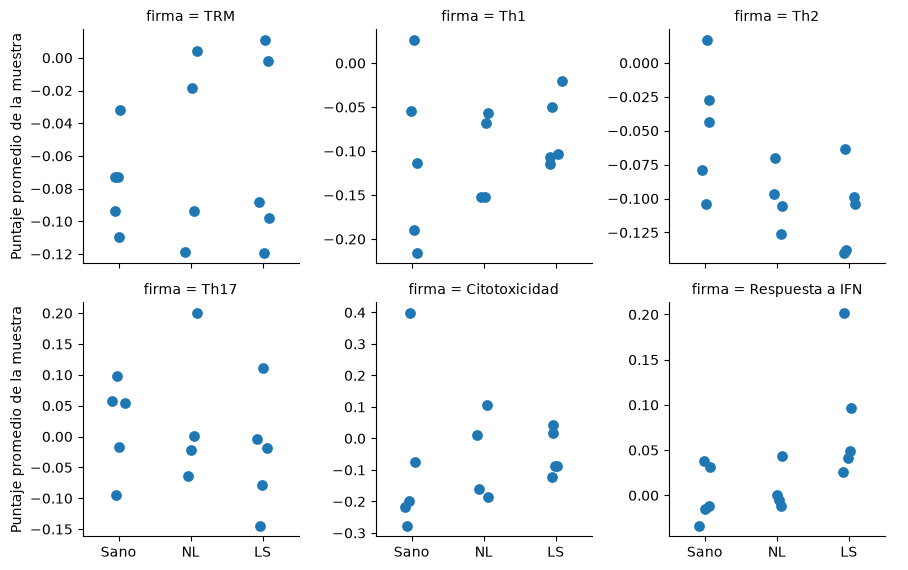

In [5]:
largo = por_muestra.reset_index().melt(id_vars=["muestra", "condicion", "n_T"],
                                       var_name="firma", value_name="puntaje")
g = sns.catplot(data=largo, x="condicion", y="puntaje", col="firma", kind="strip",
                col_wrap=3, order=["Sano", "NL", "LS"], sharey=False, height=3, s=60)
g.set_axis_labels("", "Puntaje promedio de la muestra")
g.savefig(DIR_FIGURAS / "firmas_T_por_condicion.png", dpi=150, bbox_inches="tight")

In [6]:
por_muestra.round(4).to_csv(DIR_TABLAS / "firmas_T_por_muestra.csv")